# Orthomosaic — Part 1b: Dense MVS (GPU)

![01b — dense MVS: load sparse model, dense_orthomosaic (GPU patch_match_stereo via dense_mvs_pool), shared-ENU products, dense cloud plus LAZ](https://raw.githubusercontent.com/databrickslabs/geobrix/main/resources/images/diagrams/orthomosaic/orthomosaic-01b.png)

◀ **you are here** — Part 1b (dense, GPU)

Running this notebook opts into **dense** reconstruction on **GPU compute**. It loads Part 1a's persisted sparse model, undistorts each GPS cluster, runs COLMAP `patch_match_stereo` across the node's GPUs via GeoBrix `dense_mvs_pool` (a driver-side GPU-slot scheduler), fuses the depth maps, and writes a dense RGB ortho + DSM + LAZ. `GPU = True` (set below, before `%run ./config_nb`) is what tells `config_nb` this is the GPU run.

> **Runtime.** Serverless GPU AI Runtime, **environment 6** (pycolmap-cuda12, CUDA 12). The CPU peer is Part 1a (01a_sfm_orthomosaic), which produces the sparse orthomosaic + the persisted sparse model this notebook loads.

---

**Last Update:** September 30, 2026

> **Recommended environment: Databricks AI Runtime on a GPU cluster — `GPU_8xH100` (or comparable).**
>
> Dense MVS (`patch_match_stereo`) is **CUDA-only, GPU-bound, and memory-hungry** — it needs a **beefy multi-GPU node**, not a laptop-class GPU. On **Serverless**, request the **GPU AI Runtime** (`--hardware-accelerator GPU_8xH100`; select **environment 6**, which is CUDA 12, matching `pycolmap-cuda12`); on a **classic** cluster use a large-RAM multi-GPU node. A small / single-GPU node is slow and can exhaust host RAM. GeoBrix's `recommend_dense_allocation` fans the sparse clusters across **all available GPUs** automatically — more GPUs → more clusters densified in parallel.

## Setup

> **Environment 6.** On the Serverless GPU AI Runtime the UDF workers run environment 6, even when
> the driver runs environment 5, and an env wheel refuses to import on the other environment. Select
> **environment 6** in the notebook's Environment panel and install the **env6 wheel**, so the driver
> and the workers match.

In [0]:
# Install GeoBrix (Serverless GPU, environment 6).
%pip install --quiet --disable-pip-version-check --no-deps --force-reinstall "geobrix @ file:///Volumes/geospatial_docs/geobrix/sample-data/geobrix-0.6.0+env6-py3-none-any.whl"
%pip install --quiet "geobrix[vizx] @ file:///Volumes/geospatial_docs/geobrix/sample-data/geobrix-0.6.0+env6-py3-none-any.whl"
%pip install --quiet "pycolmap-cuda12==4.2.1"
%restart_python

GeoBrix 0.6.0+env6 installed (build b5dbc078163e, wheel sha256 244b89185146) on Serverless environment 6 (GPU_8xH100)


In [0]:
%run ./config_nb

geobrix 0.6.0: one wheel per runtime (+env5 / +env6); SQL functions register through databricks.labs.gbx.register(spark); the Python API is rasterx / gridx / vectorx. See https://databrickslabs.github.io/geobrix/docs/migration-0-6
geobrix: heavy (Catalyst) unavailable: Spark Connect session (Serverless); using light (48 functions)
geobrix: SQL unavailable: 5 functions (gbx_bng_cellarea, gbx_bng_eastnorthasbng, gbx_quadbin_distance, ...) need a SQL function wrapper, and SQL functions are unavailable here; using light


### Optional: a faster “taste” of dense MVS (opt-in)

By **default this notebook densifies the FULL sparse reconstruction** from Part 1a — the full orthomosaic. For a quick, lower-fidelity preview (much faster, and runnable on a smaller GPU), uncomment the settings in the next cell: one cluster and its first 8 images (dense keeps the full 1600 px resolution — the speed-up is the smaller image set, not downscaling). **Pair with Part 1a's matching opt-in** so its sparse model is built at the same scale. Leave all three commented for the full run.

In [0]:
# --- Optional dev "taste": a MINIMAL dense reconstruction instead of the full one ---
# Uncomment to preview quickly; leave commented (default) for the FULL run. Pair with the
# matching opt-in in nb1a so its sparse model is built at the same 8-image scale.
# DEV_MAX_IMAGES = 8          # densify only this cluster's first 8 images (needs nb1a's dev model)
# SUBSET_CLUSTER = 0          # densify only GPS cluster 0
# DENSE_MAX_IMAGE_SIZE = 1600  # keep full res; 800 starved the cloud (no usable dense)

In [0]:
# nb1b requires GPU compute (dense patch_match needs CUDA). Assert the driver sees a GPU.
from databricks.labs.gbx.rasterx import mvs
_infra = mvs.gpu_infra()
assert _infra["gpu_count"] >= 1, (
    "nb1b needs GPU compute (0 CUDA devices on the driver). Run on Serverless GPU AI Runtime, "
    "or run nb1a alone for the sparse orthomosaic."
)
print(f"[nb1b] GPU: {_infra['gpu_count']}x, {_infra.get('per_gpu_vram_mb',0)//1024}GB VRAM each, "
      f"{_infra.get('host_ram_mb',0)//1024}GB host RAM, {_infra.get('cores',0)} cores "
      f"(driver {_infra.get('driver','?')}, CUDA {_infra.get('cuda','?')})")

[nb1b] GPU: 8x, 79GB VRAM each, 1999GB host RAM, 192 cores (driver 595.91.07, CUDA 13.2)


> **Compute note.** Sparse SfM runs **CPU-distributed** (per-image extraction + per-pair matching as Spark tasks) even on this GPU node — per-task CUDA init on a shared GPU makes GPU sparse counterproductive here. The **GPU is used for the dense MVS stage** (`patch_match_stereo`), a single per-cluster context. Dense lands in a following step.

## Stage the image dataset (idempotent)

Download the [Old Orchard DroneDB dataset](https://hub.dronedb.app/r/odm/old-orchard) from
GitHub to the series' Volume (`DOWNLOAD_DIR` in `config_nb`), where `exif_gbx` and the
Serverless workers read them. The `FORCE_DOWNLOAD=False` guard skips the fetch when images are already staged.

In [0]:
import time as _time_import  # time imported in config_nb; alias for clarity

img_path = str(Path(DOWNLOAD_DIR).resolve())

# Per-file staging: always fetch the authoritative GitHub listing, then download
# only the images MISSING locally (fill gaps in a partial download) instead of
# skipping wholesale when >=1 file is already present. FORCE_DOWNLOAD=True
# re-fetches every file even if present; otherwise each file already on disk is
# kept. (Lists the repo every run via the cheap contents API so an incomplete
# local set is completed rather than skipped.)
_t = _time_import.perf_counter()
image_files = [f for f in iter_repo_files(GH_DATASET_PATH) if is_image(f["path"])]
_fetched = _kept = 0
for fi in image_files:
    _out = Path(DOWNLOAD_DIR) / Path(fi["path"]).relative_to(GH_DATASET_PATH)
    if _out.exists() and not FORCE_DOWNLOAD:
        _kept += 1
        continue
    download_file(fi, DOWNLOAD_DIR, force=FORCE_DOWNLOAD)
    _fetched += 1
staged = [p for p in Path(DOWNLOAD_DIR).rglob("*") if p.suffix.lower() in (".jpg", ".jpeg")]
print(f"{len(image_files)} source images: {_fetched} fetched "
      f"({'FORCE_DOWNLOAD' if FORCE_DOWNLOAD else 'missing-only'}), {_kept} kept; "
      f"{len(staged)} staged at {img_path} in {_time_import.perf_counter()-_t:.1f}s")

171 source images: 0 fetched (missing-only), 171 kept; 171 staged at /Volumes/geospatial_docs/orthomosaic/data/gopro/images/OldOrchard_2017-07-22 in 2.8s


## Preview: the raw input images (the “before”)

Before any processing, the input is just a pile of **overlapping drone photos** — each
carries per-image GPS but has no alignment to its neighbors or to the ground. The contact
sheet below samples the raw frames so the challenge is visible: Structure-from-Motion must
recover every camera’s pose and a sparse 3-D scene, which we then back-project into a
single georeferenced orthomosaic.

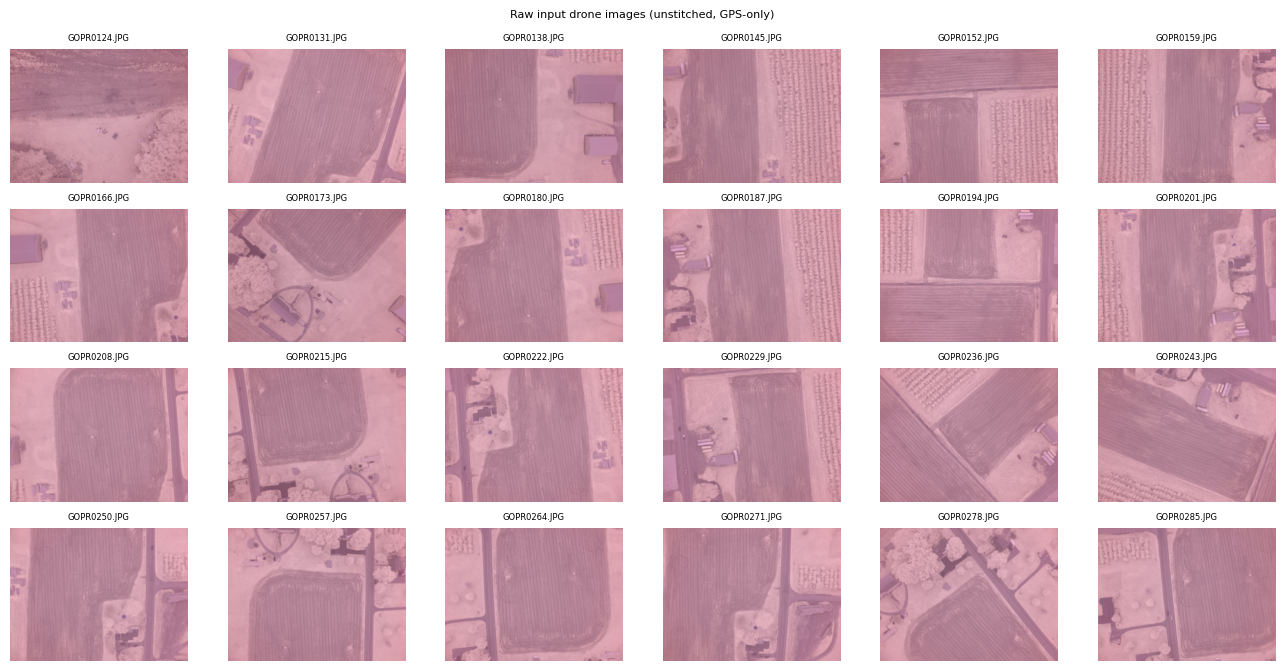

In [0]:
# Contact sheet of the raw inputs: an evenly-spaced sample of the overlapping,
# GPS-only drone frames that SfM must align and stitch. vz.plot_gallery previews
# any image/raster collection as a thumbnail grid (the small-multiples of plot_file).
_ = vz.plot_gallery(
    img_path,
    mode="sample",
    limit=24,
    cols=6,
    title="Raw input drone images (unstitched, GPS-only)",
)

## Extract EXIF + GPS metadata with GeoBrix `exif_gbx`

**GeoBrix `exif_gbx`** — a Serverless-safe DataSource V2 reader — extracts per-file EXIF
metadata, GPS coordinates (as WKB geometry), focal length, sensor width, and image
dimensions without hand-rolling PIL loops.

`mode="qc"` additionally computes `sharpness` and `brightness` pixel metrics in the same
pass (no second image decode), saving one full round-trip over the file set.

In [0]:
import time as _t_exif

_t0 = _t_exif.perf_counter()
try:
    # Auto-detect the collection's COMMON EXIF intrinsics (uniform focal + a
    # camera-model sensor-width lookup) and surface an evaluation of what is
    # common / present-but-variable / missing. Explicit config still wins.
    from databricks.labs.gbx.ds.exif import build_exif_common_opts
    _exif_opts, _exif_report = build_exif_common_opts(img_path, mode="sample", limit=24)
    _exif_opts["mode"] = "qc"
    if SENSOR_WIDTH_MM is not None:
        _exif_opts["sensorWidthMm"] = str(SENSOR_WIDTH_MM)
    if FOCAL_LENGTH_MM is not None:
        _exif_opts["focalLengthMm"] = str(FOCAL_LENGTH_MM)
    print("[exif] common opts:", _exif_opts)
    print("[exif] classification:", _exif_report["classification"])
    for _s in _exif_report["suggestions"]:
        print("   [exif] suggestion:", _s)

    # spark.read.format("exif_gbx") — one row per image; no PIL loop needed.
    df_meta = (
        spark.read.format("exif_gbx")
             .options(**_exif_opts)
             .load(img_path)
    )

    # Add group key: default constant group so the pipeline runs as one batch.
    # Change GROUP_KEY_COL and assign a real column here for multi-group runs.
    if GROUP_KEY_COL == "_group":
        df_meta = df_meta.withColumn("_group", F.lit("all"))
    # else: GROUP_KEY_COL already exists in the schema (e.g. derived from timestamp)

    print(f"exif_gbx: {df_meta.count()} images read in {_t_exif.perf_counter()-_t0:.1f}s")
    df_meta.select(
        "path", "latitude", "longitude", "altitude",
        "focal_length_mm", "sensor_width_mm", "image_width", "image_height",
        "sharpness", "brightness",
    ).show(5, truncate=60)
except Exception as e:
    print(f"[ERROR] exif_gbx step failed after {_t_exif.perf_counter()-_t0:.1f}s: {e}")
    raise

[exif] common opts: {'focalLengthMm': '3.0', 'mode': 'qc', 'sensorWidthMm': '6.17'}
[exif] classification: {'common': {'focal_length_mm': 3.0, 'camera_make': 'GoPro', 'camera_model': 'HERO4 Black', 'image_width': 4000, 'image_height': 3000}, 'variable': {'latitude': {'n_distinct': 24, 'examples': [43.229196400063856, 43.22934350004819, 43.229345400013955, 43.22935070001784, 43.22970330003028, 43.229724000000004]}, 'longitude': {'n_distinct': 24, 'examples': [-77.9667395, -77.9665736999626, -77.9665408, -77.96640509989486, -77.96633609998092, -77.966241799918]}, 'altitude': {'n_distinct': 24, 'examples': [153.91, 256.18, 256.36, 256.59, 256.89, 257.42]}, 'timestamp': {'n_distinct': 24, 'examples': [datetime.datetime(2015, 1, 1, 0, 3, 56), datetime.datetime(2015, 1, 1, 0, 4, 44), datetime.datetime(2015, 1, 1, 0, 5, 1), datetime.datetime(2015, 1, 1, 0, 5, 14), datetime.datetime(2015, 1, 1, 0, 5, 26), datetime.datetime(2015, 1, 1, 0, 5, 40)]}}, 'missing': {'sensor_width_mm': 0.0}}
   [exif

## Quality-control filter

Remove blurry or underexposed images before SfM.

- **Sharpness** — keep images with sharpness ≥ 50% of the batch median.
- **Brightness** — keep images in the range [20, 240] (discard over- and under-exposed).

The `sharpness` and `brightness` columns were populated by `exif_gbx` mode `"qc"` using the
same `image_sharpness` / `image_brightness` scalars from `databricks.labs.gbx.rasterx.imagery`.

In [0]:
import time as _t_qc

_t0 = _t_qc.perf_counter()
try:
    window_spec = Window.partitionBy(GROUP_KEY_COL)
    df_qc = (
        df_meta
        .withColumn("median_sharpness", F.percentile_approx("sharpness", 0.5).over(window_spec))
        .filter(F.col("sharpness") >= F.col("median_sharpness") * 0.5)
        .filter((F.col("brightness") > 20) & (F.col("brightness") < 240))
        .withColumn("gps_geom", F.expr("st_point(longitude, latitude)"))
        .withColumnRenamed("path", "source")
    )
    n_before = df_meta.count()
    n_after  = df_qc.count()
    print(f"QC filter: {n_before} → {n_after} images retained "
          f"({n_before - n_after} removed) in {_t_qc.perf_counter()-_t0:.1f}s")
except Exception as e:
    print(f"[ERROR] QC filter failed after {_t_qc.perf_counter()-_t0:.1f}s: {e}")
    raise

QC filter: 171 → 171 images retained (0 removed) in 38.5s


## Validate GPS coverage

Warn before SfM if fewer than 3 images have valid GPS — incremental mapping will proceed
but without GPS-constrained bundle adjustment, which reduces georeferencing accuracy.

In [0]:
gps_ok_count = df_qc.filter(
    F.col("latitude").isNotNull() & F.col("longitude").isNotNull() & F.col("altitude").isNotNull()
).count()
total_count = df_qc.count()
print(f"GPS coverage: {gps_ok_count}/{total_count} images have valid lat/lon/altitude")
if gps_ok_count < 3:
    print("[WARN] Fewer than 3 images have GPS — incremental mapping will proceed without "
          "GPS-constrained BA. Georeferencing accuracy may be reduced.")

GPS coverage: 171/171 images have valid lat/lon/altitude


## Run distributed SfM (one orthomosaic per `GROUP_KEY_COL` value)

For each distinct value of `GROUP_KEY_COL`, collect the image subset and run
`sfm.run_sfm` — feature extraction, geospatial pair discovery, distributed matching,
and incremental mapping via `pycolmap`.

The `GROUP_KEY_COL = "_group"` default runs all images as a single group.
Set `GROUP_KEY_COL` to a metadata column (e.g. `"flight_date"`) and pass a real column
value to run the pipeline for each flight.

In [0]:
# nb1b LOADS nb1a's PERSISTED sparse model directly — it does NOT run SfM extraction.
# nb1b installs pycolmap-cuda12 (for GPU dense); the distributed CPU-SIFT extraction cannot
# import the CUDA build on GPU-less mapInPandas executors, so extraction is nb1a's job. Here we
# just read the persisted sparse model + GPS priors that nb1a wrote to the Volume.
from pathlib import Path as _Path
groups = [row[GROUP_KEY_COL] for row in df_qc.select(GROUP_KEY_COL).distinct().collect()]
cluster_models = {}
for grp in groups:
    _proot = _Path(group_paths(grp)["sfm_persist"])
    cluster_models[grp] = {}
    _cands = {}
    for _cdir in sorted(_proot.glob("cluster_*")):
        _sp = _cdir / "sparse"
        _gj = _cdir / "gps_priors.json"
        if not (_sp.exists() and _gj.exists()):
            continue
        _nm = _cdir.name[len("cluster_"):]
        _cid = int(_nm.split("_")[0]) if _nm.split("_")[0].isdigit() else _nm
        _cands.setdefault(_cid, []).append(("_dev" in _nm, str(_sp), str(_gj)))
    # Prefer canonical cluster_<cid> over a cluster_<cid>_dev<N> artifact when both exist,
    # so a full run never picks up a small dev model; an isolated dev dir has only the
    # _dev model, so it is still used there.
    for _cid, _lst in _cands.items():
        _lst.sort(key=lambda t: t[0])
        cluster_models[grp][_cid] = (_lst[0][1], _lst[0][2])
    # Dev: SUBSET_CLUSTER=<idx> densifies only that GPS cluster (fast dev loop; mirrors
    # nb1a's SUBSET_CLUSTER). Applied per group before dense so undistort/patch_match
    # only touch one cluster.
    _subset = globals().get("SUBSET_CLUSTER", None)
    if _subset is not None and cluster_models[grp]:
        _cids = sorted(cluster_models[grp])
        if int(_subset) < len(_cids):
            _keep = _cids[int(_subset)]
            cluster_models[grp] = {_keep: cluster_models[grp][_keep]}
            print(f"[nb1b][dev] SUBSET_CLUSTER={_subset}: group {grp!r} \u2192 only cluster {_keep}")
    print(f"[nb1b] group {grp!r}: loaded {len(cluster_models[grp])} persisted sparse cluster(s) from {_proot}")
    if not cluster_models[grp]:
        raise RuntimeError(
            f"nb1b: no persisted sparse model for group {grp!r} at {_proot}. "
            "Run nb1a first — it builds + persists the sparse model this notebook consumes."
        )

[nb1b] group 'all': loaded 4 persisted sparse cluster(s) from /Volumes/geospatial_docs/orthomosaic/data/gopro/outputs/OldOrchard_2017-07-22_result/group_all/sfm


## Compute GSD via GeoBrix `gsd_from_telemetry`

**GeoBrix `gsd_from_telemetry`** computes ground sampling distance in cm/pixel from
altitude (m), focal length (mm), sensor width (mm), and image width (px) using the
standard pinhole-camera formula:

```
GSD (cm/px) = sensor_mm × alt_m × 100 / (focal_mm × width_px)
```

This matches the formula used by OpenDroneMap and COLMAP documentation.

In [0]:
import time as _t_gsd

_t0 = _t_gsd.perf_counter()
try:
    # Use exif_gbx columns (sensor_width_mm, focal_length_mm) + config override fallbacks.
    _sw_col = F.coalesce(F.col("sensor_width_mm"), F.lit(SENSOR_WIDTH_MM))
    _fl_col = F.col("focal_length_mm") if FOCAL_LENGTH_MM is None else F.lit(FOCAL_LENGTH_MM)

    df_gsd = df_qc.withColumn(
        "gsd_cm",
        gsd_udf(
            F.col("altitude").cast("double"),
            _fl_col.cast("double"),
            _sw_col.cast("double"),
            F.col("image_width").cast("double"),
        ),
    )
    stats   = df_gsd.agg(F.avg("gsd_cm"), F.min("gsd_cm"), F.max("gsd_cm")).collect()[0]
    avg_gsd = stats[0]
    print(f"GSD: avg={avg_gsd:.2f} cm/px  min={stats[1]:.2f}  max={stats[2]:.2f}  "
          f"({_t_gsd.perf_counter()-_t0:.1f}s)")

    # Use config GSD_CM if set; otherwise auto-derive from image telemetry.
    gsd_for_ortho = GSD_CM if GSD_CM is not None else round(avg_gsd, 1)
    print(f"Using GSD_CM={gsd_for_ortho:.1f} cm/px for orthomosaic rendering.")
except Exception as e:
    print(f"[ERROR] GSD step failed after {_t_gsd.perf_counter()-_t0:.1f}s: {e}")
    raise

GSD: avg=13.26 cm/px  min=7.91  max=13.40  (23.6s)
Using GSD_CM=13.3 cm/px for orthomosaic rendering.


## Dense MVS (GPU) → dense ortho + DSM + LAS/LAZ

One call — `rasterx.ortho.dense_orthomosaic` — reconstructs every GPS cluster and writes the georeferenced products. Under the hood it composes two library functions: `dense_reconstruct_clusters` (undistort each cluster against the sparse model, run COLMAP `patch_match_stereo` across the node's GPUs via a GPU-slot scheduler, and fuse depth maps to `fused.ply`, with per-cluster Volume checkpointing) and `dense_clusters_to_products`, which places every cluster in **ONE shared ENU frame** — the anchor cluster georeferenced to GPS, neighbours tied through their shared overlap cameras (the same frame the sparse `ortho.sparse_orthomosaic` uses) — and writes:

- a **per-cluster** dense RGB ortho + DSM, named `…_<group>_<cluster>` (e.g. `orthomosaic_dense_all_0.tif`, `dsm_dense_all_0.tif`), one set per GPS cluster;
- **sharded LAZ parts** written via the `lidar_gbx` DataSource writer (phase 1): `*_<group>_<cluster>.laz` parts, one shard per cluster, all under the group's dense output directory; and
- a **merged `dense_merged.laz`** (phase 2): all cluster parts folded into one cloud with `keepParts=True` so the individual shards are retained, and `overlap="drop"` so each seam point is owned by exactly one cluster — `dense_merged.laz` is a non-redundant, seam-de-duplicated union, not a raw concatenation with duplicate overlap-band points. Also: a **single co-registered merged** `orthomosaic_dense.tif` + `dsm_dense.tif` — the group deliverable the downstream notebooks consume.

Allocation across GPUs (count, VRAM, image resolution) is auto-tuned internally (`mvs.recommend_dense_allocation`) before the patch_match pool is launched. Dev can restrict to a single GPS cluster (`SUBSET_CLUSTER`); the full survey densifies **and merges every cluster** (recommended on `GPU_8xH100`).

> **Checkpoint.** Dense is checkpointed per cluster via `checkpoint.Manifest` — each cluster's `fused.ply` is persisted to the Volume; a re-run skips completed clusters and re-does only the (CPU) georeference + merge (set `FORCE_DENSE=True` to recompute).

In [0]:
import time as _t_dense
from databricks.labs.gbx.rasterx import checkpoint, mvs
from databricks.labs.gbx.rasterx import ortho

# Dense MVS resolution + speed knobs. geom_consistency=False is the fast lever (photometric fusion); it is the SAFE
# fast lever (~2x: skips the geometric refinement pass) WITHOUT starving the cloud.
# The src-images / iterations / window-step knobs default to COLMAP quality — capping
# ALL of them together produced a degenerate cloud (empty ground band). --set-var to
# tune per run. globals().get keeps runner-injected overrides.
# Orchestration (undistort -> patch_match pool -> fuse -> georef) is now ONE call per group:
# rasterx.ortho.dense_orthomosaic — see the markdown cell above for what it produces.
DENSE_MAX_IMAGE_SIZE = globals().get("DENSE_MAX_IMAGE_SIZE", 1600)
DENSE_SRC_IMAGES     = globals().get("DENSE_SRC_IMAGES", None)            # source imgs/reference (None=all)
DENSE_GEOM_CONSIST   = bool(globals().get("DENSE_GEOM_CONSIST", False))   # ON=geometric (~2x, higher quality); OFF=photometric fusion (fast)
DENSE_ITERS          = globals().get("DENSE_ITERS", None)                 # None = COLMAP default (5)
DENSE_WINDOW_STEP    = globals().get("DENSE_WINDOW_STEP", None)           # None = COLMAP default (1)

_infra = mvs.gpu_infra()
print(f"[dense] GPU {_infra['gpu_count']}x (driver {_infra.get('driver','?')}, CUDA {_infra.get('cuda','?')}) | "
      f"knobs: max_image_size={DENSE_MAX_IMAGE_SIZE}, src_images={DENSE_SRC_IMAGES}, "
      f"geom_consistency={DENSE_GEOM_CONSIST}, iters={DENSE_ITERS}, window_step={DENSE_WINDOW_STEP}")

_t0 = _t_dense.perf_counter()
dense_paths, dense_clouds = {}, {}
for grp in groups:
    cmods = cluster_models.get(grp, {})
    if not cmods:
        print(f"[WARN] group {grp!r}: no cluster models — skipping dense")
        continue
    gp = group_paths(grp)
    _dev_n = globals().get("DEV_MAX_IMAGES", None)
    _devsuf = f"_dev{int(_dev_n)}" if _dev_n else ""   # dev runs isolate under a suffixed root
    used, merged = ortho.dense_orthomosaic(
        spark, cmods, img_path,
        merged_ortho=gp["dense_ortho"], merged_dsm=gp["dense_dsm"], merged_laz=gp["dense_cloud"],
        cluster_paths={cid: dense_cluster_paths(grp, cid) for cid in cmods},
        work_root=f'{gp["sfm_dir"]}/dense{_devsuf}', ply_root=f'{gp["sfm_persist"]}/dense{_devsuf}',
        checkpoint=checkpoint.Manifest(gp["checkpoint"]), force=bool(FORCE_DENSE),
        gsd_cm=gsd_for_ortho, group=grp,
        max_image_size=DENSE_MAX_IMAGE_SIZE, src_images=DENSE_SRC_IMAGES,
        geom_consistency=DENSE_GEOM_CONSIST, num_iterations=DENSE_ITERS, window_step=DENSE_WINDOW_STEP,
        on_event=print)
    dense_clouds[grp] = merged
    dense_paths[grp] = gp["dense_ortho"]
    print(f"[dense] group {grp!r}: {len(used)} cluster(s) -> merged dense products")
print(f"[dense] done in {_t_dense.perf_counter() - _t0:.0f}s → {list(dense_paths.values())}")

[dense] GPU 8x (driver 595.91.07, CUDA 13.2) | knobs: max_image_size=1600, src_images=None, geom_consistency=False, iters=None, window_step=None


I20261112 08:27:20.148617 140715119990080 images.cc:124]  => Reconstruction with 53 images and 50292 points
I20261112 08:27:20.148935 140715119990080 undistorters.cc:166] === Image undistortion ===
I20261112 08:27:20.160302 140715119990080 undistorters.cc:208] Undistorting image [1/53]
I20261112 08:27:21.744783 140715119990080 undistorters.cc:208] Undistorting image [2/53]
I20261112 08:27:21.753160 140715119990080 undistorters.cc:208] Undistorting image [3/53]
I20261112 08:27:21.753184 140715119990080 undistorters.cc:208] Undistorting image [4/53]
I20261112 08:27:21.767467 140715119990080 undistorters.cc:208] Undistorting image [5/53]
I20261112 08:27:21.776138 140715119990080 undistorters.cc:208] Undistorting image [6/53]
I20261112 08:27:21.776151 140715119990080 undistorters.cc:208] Undistorting image [7/53]
I20261112 08:27:21.776157 140715119990080 undistorters.cc:208] Undistorting image [8/53]
I20261112 08:27:21.784350 140715119990080 undistorters.cc:208] Undistorting image [9/53]
I

[place] cluster 2: tied via 30 shared cameras
[place] cluster 0: tied via 22 shared cameras
[place] cluster 3: tied via 20 shared cameras
[place] 4/4 clusters placed in shared ENU (3 via shared cameras, anchor 1)
Dense ortho → /Volumes/geospatial_docs/orthomosaic/data/gopro/outputs/OldOrchard_2017-07-22_result/group_all/orthomosaic_dense_all_1.tif  DSM → /Volumes/geospatial_docs/orthomosaic/data/gopro/outputs/OldOrchard_2017-07-22_result/group_all/dsm_dense_all_1.tif  (2462×2484px @ 13.3cm)
Dense ortho → /Volumes/geospatial_docs/orthomosaic/data/gopro/outputs/OldOrchard_2017-07-22_result/group_all/orthomosaic_dense_all_2.tif  DSM → /Volumes/geospatial_docs/orthomosaic/data/gopro/outputs/OldOrchard_2017-07-22_result/group_all/dsm_dense_all_2.tif  (2278×3053px @ 13.3cm)
Dense ortho → /Volumes/geospatial_docs/orthomosaic/data/gopro/outputs/OldOrchard_2017-07-22_result/group_all/orthomosaic_dense_all_0.tif  DSM → /Volumes/geospatial_docs/orthomosaic/data/gopro/outputs/OldOrchard_2017-07-22

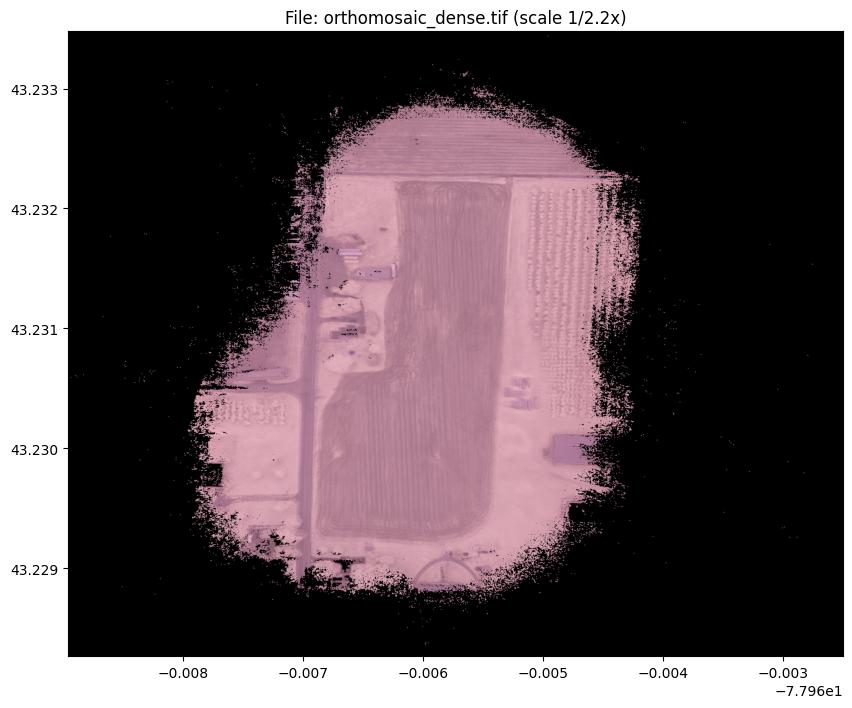

In [0]:
# Render the dense ortho (sharper than the sparse flat-plane back-projection).
if dense_paths:
    vz.plot_file(list(dense_paths.values())[0])

## Verify the dense cloud (lidar_gbx)

Read the exported LAZ back through the `lidar_gbx` metadata reader to confirm the merged point cloud (`dense_merged.laz`) round-trips — a non-zero `point_count` is the check that the two-phase dense export is well-formed and consumable by the LiDAR raster functions. The merge uses `overlap="drop"`, so `dense_merged.laz` is a seam-de-duplicated, non-redundant union of the per-cluster clouds (each seam point owned by exactly one cluster) rather than a raw concatenation with duplicate overlap-band points. (Per-cluster sharded parts are kept under the same directory and also readable via `lidar_gbx` as a directory of parts.)

In [0]:
# Verify the exported dense point cloud(s) round-trip through lidar_gbx — the
# MERGED cloud AND each per-cluster cloud, so every export is confirmed well-formed
# and consumable by the LiDAR raster functions (a non-zero point_count is the check).
from pathlib import Path as _P

_to_verify = []
for _grp, _laz in dense_clouds.items():
    _to_verify.append((f"{_grp} (merged)", _laz))
    for _cid in sorted(cluster_models.get(_grp, {})):
        _cp = dense_cluster_paths(_grp, _cid)["cloud"]
        # write_xyzrgb_laz may fall back .laz -> .las; take whichever exists.
        for _cand in (_cp, str(_P(_cp).with_suffix(".las"))):
            if _P(_cand).exists():
                _to_verify.append((f"{_grp}::cluster {_cid}", _cand))
                break
for _label, _laz in _to_verify:
    try:
        _meta = spark.read.format("lidar_gbx").option("mode", "metadata").load(_laz)
        _row = _meta.select(
            "point_count", "x_min", "x_max", "z_min", "z_max", "crs"
        ).collect()[0]
        print(f"lidar_gbx: {_label} → point_count={_row['point_count']:,} "
              f"z=[{_row['z_min']:.1f}, {_row['z_max']:.1f}] crs={_row['crs']}")
    except Exception as _e:  # noqa: BLE001
        print(f"[WARN] lidar_gbx read of {_laz} failed: {_e}")

lidar_gbx: all (merged) → point_count=3,143,129 z=[-163.6, -6.7] crs=EPSG:32618
lidar_gbx: all::cluster 0 → point_count=1,358,923 z=[-121.6, -8.3] crs=EPSG:32618
lidar_gbx: all::cluster 1 → point_count=1,958,786 z=[-163.6, -6.7] crs=EPSG:32618
lidar_gbx: all::cluster 2 → point_count=1,332,512 z=[-93.5, -13.8] crs=EPSG:32618
lidar_gbx: all::cluster 3 → point_count=1,248,710 z=[-170.5, -34.9] crs=EPSG:32618


### Render the dense cloud as points

The metadata round-trip above confirms the cloud is well-formed; here we *see* it. `vz.plot_point_cloud` renders `dense_merged.laz` as a true-color **3-D** point cloud — the dense reconstruction as **points**, not just its derived ortho/DSM raster. With `INTERACTIVE=True` it is a live deck.gl orbit view; by default (`INTERACTIVE=False`) it renders a static RGB 3-D PNG (what GitHub shows).

/local_disk0/.ephemeral_nfs/envs/pythonEnv-149668a6-02ea-4f2f-ab1c-a04772bd2238/lib/python3.12/site-packages/databricks/labs/gbx/vizx/_pmtiles.py:269: UserWarning: load_point_cloud: 3143129 points decimated to 300000 (raise max_points to render more).
  x, y, z, values, rgb, _src_crs = load_point_cloud(


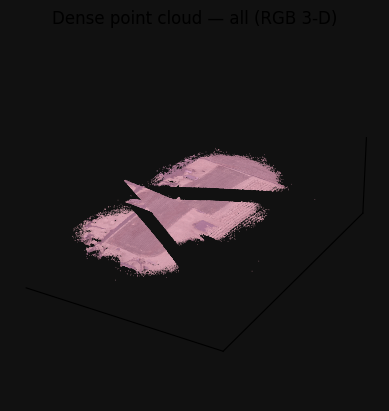

In [0]:
# Render the dense cloud AS POINTS (not only as the derived ortho/DSM raster): a
# true-color 3-D point cloud of the merged dense cloud via vizx plot_point_cloud
# -- a visual sanity check of the 3-D reconstruction alongside the metadata
# round-trip above. INTERACTIVE=True gives a live deck.gl orbit; the default
# (INTERACTIVE=False -> max_embed_mb=0) renders a static RGB 3-D PNG for GitHub.
# Points beyond max_points are decimated so the render stays in memory.
from pathlib import Path as _P

for _grp, _laz in dense_clouds.items():
    _cloud = _laz if _P(_laz).exists() else str(_P(_laz).with_suffix(".las"))
    if not _P(_cloud).exists():
        print(f"[skip] {_grp}: no merged cloud to render ({_laz})")
        continue
    vz.plot_point_cloud(
        _cloud,
        color="rgb",
        point_size=1.0,
        max_embed_mb=(None if INTERACTIVE else 0),
        title=f"Dense point cloud — {_grp} (RGB 3-D)",
    )
    break  # one representative render; per-cluster clouds are verified above

## Visualize — per-cluster dense tiles

The merged dense orthomosaic is rendered above; here is each GPS cluster's dense ortho on its own — confirming every cluster densified before they are blended into the single merged product.

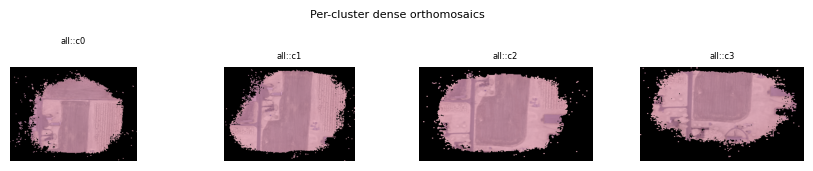

In [0]:
# Per-cluster dense orthos: a gallery confirming EVERY GPS cluster was densified
# (the merged ortho rendered above blends them into one seamless product). Falls
# back to the sparse ortho only if no dense product exists this run.
from pathlib import Path as _P

_tiles, _labels = [], []
for grp in groups:
    for cid in sorted(cluster_models.get(grp, {})):
        _op = dense_cluster_paths(grp, cid)["ortho"]
        if _P(_op).exists():
            _tiles.append(_op)
            _labels.append(f"{grp}::c{cid}")
if _tiles:
    vz.plot_gallery(
        _tiles, labels=_labels, renderer="raster",
        cols=min(4, len(_tiles)), title="Per-cluster dense orthomosaics",
    )
else:
    _shown = [g for g in groups if _P(group_paths(g)["ortho"]).exists()]
    if _shown:
        vz.plot_file(
            group_paths(_shown[0])["ortho"],
            title="Sparse orthomosaic (no dense product this run)",
        )
    else:
        print("[skip] no orthomosaic produced this run (no cluster reconstructed)")

## Steps performed

1. **Download** — fetched the Old Orchard drone imagery from GitHub (idempotent).
2. **EXIF/GPS extraction** — `exif_gbx` (GeoBrix) read metadata + sharpness/brightness in one pass.
3. **QC filter** — retained images above the per-group sharpness p50 × 0.5 and within the brightness window.
4. **GPS validation** — warned when fewer than 3 images have valid altitude.
5. **Distributed SfM** — feature extraction, `ST_DistanceSphere` (Databricks) pair discovery, distributed matching, and incremental mapping via `pycolmap`.
6. **GSD** — computed via `gsd_from_telemetry` (GeoBrix) from altitude, focal length, sensor size, and image width.
7. **Dense MVS (GPU)** — one call, `rasterx.ortho.dense_orthomosaic`, per group: densified each cluster with COLMAP `patch_match_stereo` (checkpointed per cluster), placed all clusters in one shared ENU frame, and wrote per-cluster ortho + DSM plus a single merged ortho + DSM. LAZ export used the `lidar_gbx` DataSource writer in two phases: phase 1 = sharded `*_<group>_<cluster>.laz` parts (one per cluster); phase 2 = `dense_merged.laz` merged from all parts (keepParts=True so shards are retained, overlap="drop" so the merge is a seam-de-duplicated, non-redundant union).

**Next:** Part 2 applies per-channel percentile color correction to remove sensor cast.